Shape: (392, 9)
Missing horsepower: 0
Shape after dropping missing: (392, 9)

  Degree  Train MSE  Test MSE
      1     24.475    22.153
      2     19.205    18.417
      3     19.144    18.460
      5     18.644    17.877
      8     18.434    17.023
     10     18.414    17.186

Optimal degree d* (min test MSE): 8


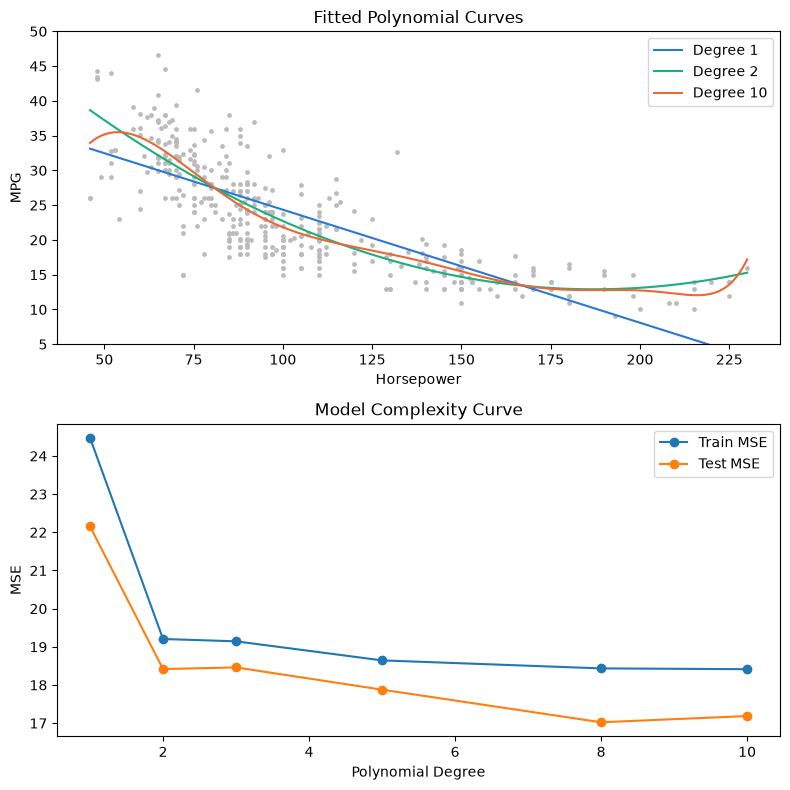

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

# 1. Load dataset from local folder (OFFLINE)
auto = pd.read_csv("Auto.csv")

print("Shape:", auto.shape)

# 2. Handle missing horsepower values
auto["horsepower"] = pd.to_numeric(
    auto["horsepower"], errors="coerce"
)

print("Missing horsepower:", auto["horsepower"].isnull().sum())

auto = auto.dropna(subset=["horsepower"])

print("Shape after dropping missing:", auto.shape)

# 3. Select input and output variables
X = auto[["horsepower"]].values
y = auto["mpg"].values

# 4. Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 5. Polynomial Regression for different degrees
degrees = [1, 2, 3, 5, 8, 10]

rows, models = [], {}

for d in degrees:

    m = make_pipeline(
        PolynomialFeatures(d),
        StandardScaler(),
        LinearRegression()
    )

    m.fit(X_train, y_train)
    models[d] = m

    rows.append([
        d,
        mean_squared_error(y_train, m.predict(X_train)),
        mean_squared_error(y_test, m.predict(X_test))
    ])

# 6. Compare model performance
res = pd.DataFrame(
    rows,
    columns=["Degree", "Train MSE", "Test MSE"]
)

print("\n", res.round(3).to_string(index=False))

print("\nOptimal degree d* (min test MSE):",
      res.loc[res["Test MSE"].idxmin(), "Degree"])

# 7. Visualization
fig, ax = plt.subplots(2, 1, figsize=(8, 8))

xs = np.linspace(X.min(), X.max(), 300).reshape(-1, 1)

ax[0].scatter(X, y, s=6, color="#bbbbbb")

for d, c in zip(
    [1, 2, 10],
    ["#2a78d6", "#1baf7a", "#eb6834"]
):
    ax[0].plot(
        xs, models[d].predict(xs),
        color=c, label=f"Degree {d}"
    )

ax[0].set_ylim(5, 50)
ax[0].set_xlabel("Horsepower")
ax[0].set_ylabel("MPG")
ax[0].legend()
ax[0].set_title("Fitted Polynomial Curves")

ax[1].plot(res["Degree"], res["Train MSE"], "o-", label="Train MSE")
ax[1].plot(res["Degree"], res["Test MSE"], "o-", label="Test MSE")

ax[1].set_xlabel("Polynomial Degree")
ax[1].set_ylabel("MSE")
ax[1].legend()
ax[1].set_title("Model Complexity Curve")


plt.tight_layout()
plt.show()
